Sample Telecom Dataset
   Monthly_Call_Minutes  Monthly_Data_Usage_GB  SMS_Per_Month  \
0                   202                     22            190   
1                   535                     28            104   
2                   960                      2            108   
3                   370                     42            197   
4                   206                     45            490   

   Monthly_Bill_Amount  
0                   20  
1                   88  
2                   23  
3                   35  
4                   43  

Clustering Evaluation Metrics

--- K-Means ---
Silhouette Score: 0.19536889598948087
Davies-Bouldin Index: 1.5896351745372417
Calinski-Harabasz Score: 48.69989450382956

--- Hierarchical Clustering ---
Silhouette Score: 0.1719265812769848
Davies-Bouldin Index: 1.706480893741493
Calinski-Harabasz Score: 41.85988784186533


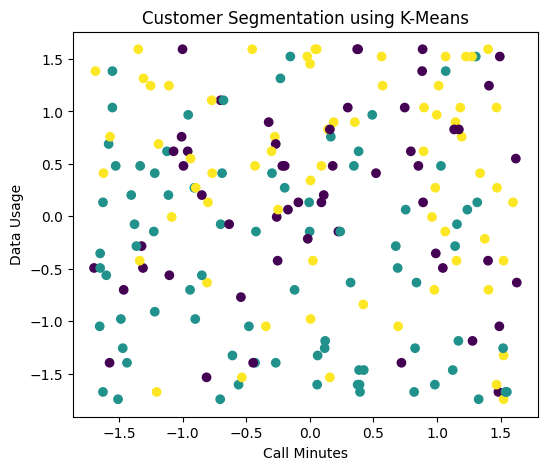

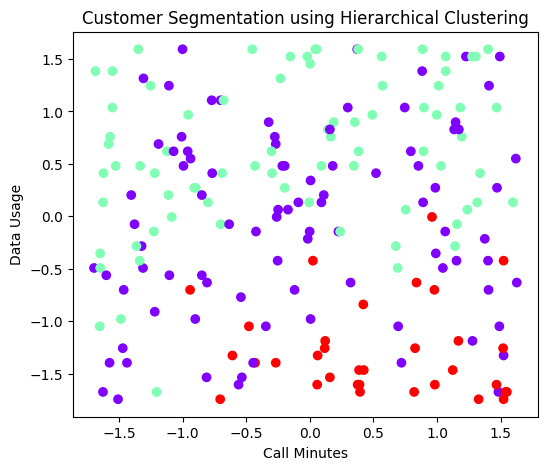

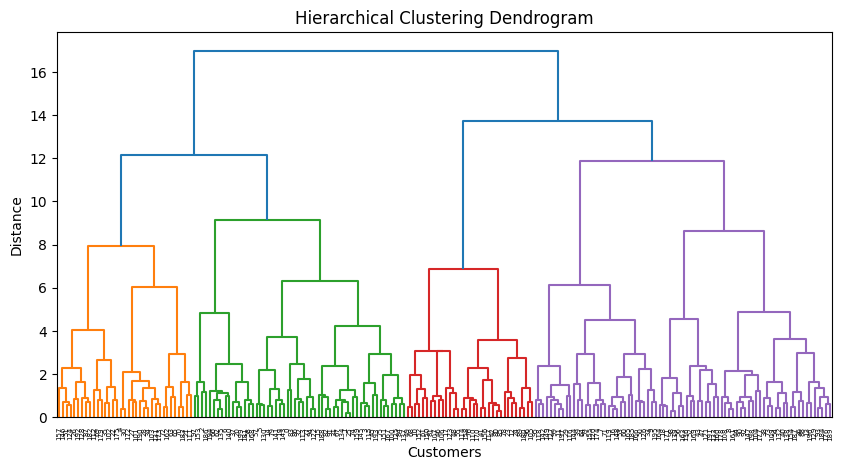

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import dendrogram, linkage

# Step 1: Create Sample Telecom Customer Dataset
np.random.seed(42)

data = pd.DataFrame({
    'Monthly_Call_Minutes': np.random.randint(100, 1000, 200),
    'Monthly_Data_Usage_GB': np.random.randint(1, 50, 200),
    'SMS_Per_Month': np.random.randint(10, 500, 200),
    'Monthly_Bill_Amount': np.random.randint(20, 200, 200)
})

print("Sample Telecom Dataset")
print(data.head())

# Step 2: Data Preprocessing
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

# Step 3: K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(scaled_data)

# Step 4: Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=3, linkage='ward'
)
hierarchical_labels = hierarchical.fit_predict(scaled_data)

# Step 5: Evaluation Metrics
print("\nClustering Evaluation Metrics")

print("\n--- K-Means ---")
print("Silhouette Score:",
      silhouette_score(scaled_data, kmeans_labels))
print("Davies-Bouldin Index:",
      davies_bouldin_score(scaled_data, kmeans_labels))
print("Calinski-Harabasz Score:",
      calinski_harabasz_score(scaled_data, kmeans_labels))

print("\n--- Hierarchical Clustering ---")
print("Silhouette Score:",
      silhouette_score(scaled_data, hierarchical_labels))
print("Davies-Bouldin Index:",
      davies_bouldin_score(scaled_data, hierarchical_labels))
print("Calinski-Harabasz Score:",
      calinski_harabasz_score(scaled_data, hierarchical_labels))

# Step 6: K-Means Visualization
plt.figure(figsize=(6, 5))
plt.scatter(scaled_data[:, 0], scaled_data[:, 1],
            c=kmeans_labels, cmap='viridis')
plt.title("Customer Segmentation using K-Means")
plt.xlabel("Call Minutes")
plt.ylabel("Data Usage")
plt.show()

# Step 7: Hierarchical Clustering Visualization
plt.figure(figsize=(6, 5))
plt.scatter(scaled_data[:, 0], scaled_data[:, 1],
            c=hierarchical_labels, cmap='rainbow')
plt.title("Customer Segmentation using Hierarchical Clustering")
plt.xlabel("Call Minutes")
plt.ylabel("Data Usage")
plt.show()

# Step 8: Dendrogram
linked = linkage(scaled_data, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()